# 03_Overnight rebalancing optimization and simulation
Turns the station-level forecasts into an overnight rebalancing plan for each test weekday, solved as a linear program with an external depot. Each plan is replayed against the actual trips of the next morning to count failed pickups and returns. A safety buffer on the forecast needs is tuned on the validation week, and the forecast-driven plans are compared with no rebalancing, a rule-based plan and a plan built on a perfect forecast.

## 1. Load data

| Name | Source | Role |
|---|---|---|
| `stations` | `data/processed/study_stations.parquet` | Station capacity and location |
| `forecasts` | `data/processed/forecasts.parquet` | Hourly LightGBM forecasts and actuals for the validation and test periods |
| `history` | `data/processed/panel.parquet` | Pre-test station history, used by the rule-based plan |
| `events` | `data/processed/trips_*.parquet` | Actual trips in the validation and test periods, replayed in the simulation |

### Assumptions

| Parameter | Value | Meaning |
|---|---|---|
| Window | 6–10 AM, weekdays | Planning and simulation window; rebalancing finishes before 6 AM |
| Starting inventory | 50% of capacity | Inventory before rebalancing; actual overnight inventory is not observed |
| `penalty` | 10 | Cost of one expected failed pickup or return |
| `cost_per_km` | 1 | Cost of moving one bike one km between stations |
| `depot_cost` | 3 | Cost of moving one bike to or from the depot outside the area |
| `max_pair_km` | 2 | Longest station-to-station move considered |
| `k` (safety buffer) | Tuned on validation | Extra bikes and docks per station, in multiples of the forecast's Poisson standard deviation |

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from scipy.sparse import coo_matrix

duckdb.sql("SET enable_progress_bar = false")
processed_dir = '../data/processed'

valid_start = '2025-09-08'
test_start, test_end = '2025-09-15', '2025-10-01'
window_start_hr, window_end_hr = 6, 10

start_fill  = 0.5
penalty     = 10.0
cost_per_km = 1.0
depot_cost  = 3.0
max_pair_km = 2.0

### Load stations and forecasts
Stations are sorted by `station_id`; every array below follows this order. Forecasts are split into the validation week and the test period.

In [2]:
stations = duckdb.sql(f"""
SELECT station_id, name, lat, lng, capacity, capacity_source
FROM '{processed_dir}/study_stations.parquet'
ORDER BY station_id
""").df()

forecasts_all = duckdb.sql(f"""
SELECT *
FROM '{processed_dir}/forecasts.parquet'
WHERE day_type = 'weekday'
  AND hr >= {window_start_hr}
  AND hr <  {window_end_hr}
""").df()

forecasts_valid = forecasts_all[forecasts_all['split'] == 'valid']
forecasts       = forecasts_all[forecasts_all['split'] == 'test']

station_ids = stations['station_id'].to_numpy()
station_idx = {s: i for i, s in enumerate(station_ids)}
cap = stations['capacity'].to_numpy()
n = len(stations)
valid_days = sorted(forecasts_valid['date'].unique())
test_days  = sorted(forecasts['date'].unique())

print(f'{n} stations')
print(f'{len(valid_days)} validation weekdays: {valid_days[0].date()} to {valid_days[-1].date()}')
print(f'{len(test_days)} test weekdays: {test_days[0].date()} to {test_days[-1].date()}')

229 stations
5 validation weekdays: 2025-09-08 to 2025-09-12
12 test weekdays: 2025-09-15 to 2025-09-30


### Load trip events for the simulation
One row per departure (−1) or arrival (+1) at a study station inside the window, in time order. The cleaning rules match `00_data_ingest`.

In [3]:
events = duckdb.sql(f"""
WITH clean AS (
    SELECT *
    FROM '{processed_dir}/trips_*.parquet'
    WHERE started_at >= '{valid_start}'
      AND started_at <  '{test_end}'
      AND date_diff('second', started_at, ended_at) BETWEEN 60 AND 3 * 3600
),
stations AS (
    SELECT station_id FROM '{processed_dir}/study_stations.parquet'
)
SELECT start_station_id AS station_id, started_at AS ts, -1 AS delta
FROM clean
WHERE start_station_id IN (SELECT station_id FROM stations)
  AND hour(started_at) >= {window_start_hr} AND hour(started_at) < {window_end_hr}
  AND dayofweek(started_at) BETWEEN 1 AND 5
UNION ALL
SELECT end_station_id, ended_at, 1
FROM clean
WHERE end_station_id IN (SELECT station_id FROM stations)
  AND hour(ended_at) >= {window_start_hr} AND hour(ended_at) < {window_end_hr}
  AND dayofweek(ended_at) BETWEEN 1 AND 5
ORDER BY ts
""").df()

events['date'] = events['ts'].dt.normalize()
events['idx'] = events['station_id'].map(station_idx)

events.groupby('date').agg(
    departures=('delta', lambda d: (d < 0).sum()),
    arrivals=('delta', lambda d: (d > 0).sum()),
)

,departures,arrivals
date,,
2025-09-08,11840,14145
2025-09-09,13829,16874
2025-09-10,8557,10121
2025-09-11,12869,15736
2025-09-12,10561,12478
2025-09-15,12001,14507
2025-09-16,13646,16681
2025-09-17,13640,16772
2025-09-18,12947,15872


## 2. Planning inputs

### Bike and dock needs per station
For each station and day, the cumulative net flow from 6 AM (arrivals − departures, hour by hour) shows how many bikes must be on hand to avoid running empty (`need_bikes`) and how many free docks are needed to avoid filling up (`need_docks`). A station's starting inventory should therefore lie between `need_bikes` and `capacity − need_docks`.

Forecasts are expected values, so planning exactly to them leaves no room for random variation. `sigma` is the Poisson standard deviation of the station's total expected trips in the window, √(departures + arrivals). A safety buffer of `k × sigma` is added to both needs, as in safety-stock planning.

In [4]:
def need_bounds(fc, dep_col, arr_col):
    fc = fc.sort_values(['station_id', 'date', 'hr']).copy()
    fc['cum_net'] = (fc[arr_col] - fc[dep_col]).groupby([fc['station_id'], fc['date']]).cumsum()
    fc['gross'] = fc[arr_col] + fc[dep_col]
    bounds = fc.groupby(['station_id', 'date']).agg(
        cum_min=('cum_net', 'min'),
        cum_max=('cum_net', 'max'),
        gross=('gross', 'sum'),
    ).reset_index()
    bounds['need_bikes'] = (-bounds['cum_min']).clip(lower=0)
    bounds['need_docks'] = bounds['cum_max'].clip(lower=0)
    bounds['sigma'] = np.sqrt(bounds['gross'])
    return bounds[['station_id', 'date', 'need_bikes', 'need_docks', 'sigma']]

bounds_valid  = need_bounds(forecasts_valid, 'departures_lgbm', 'arrivals_lgbm')
bounds_lgbm   = need_bounds(forecasts, 'departures_lgbm', 'arrivals_lgbm')
bounds_actual = need_bounds(forecasts, 'departures', 'arrivals')

def bounds_for_day(bounds, day, k=0.0):
    b = bounds[bounds['date'] == day].set_index('station_id').reindex(station_ids).fillna(0)
    buffer = k * b['sigma'].to_numpy()
    lower = b['need_bikes'].to_numpy() + buffer
    upper = cap - b['need_docks'].to_numpy() - buffer
    return lower, upper

### Conflicting stations
A station whose `need_bikes` exceeds `capacity − need_docks` cannot avoid every failure with a single overnight refill. Counted per day, using the LightGBM forecast.

In [5]:
conflicts = []
for day in test_days:
    lower, upper = bounds_for_day(bounds_lgbm, day)
    conflicts.append({'date': day.date(), 'conflicting_stations': int((lower > upper).sum())})

pd.DataFrame(conflicts)

,date,conflicting_stations
0,2025-09-15,10
1,2025-09-16,11
2,2025-09-17,10
3,2025-09-18,11
4,2025-09-19,8
5,2025-09-22,8
6,2025-09-23,11
7,2025-09-24,14
8,2025-09-25,10
9,2025-09-26,7


## 3. Optimization model

### Linear program
For each test day, the model chooses each station's starting inventory and the moves that produce it.

| Variable | Meaning |
|---|---|
| `s_i` | Starting inventory at station *i* after rebalancing, between 0 and capacity |
| `x_ij` | Bikes moved from station *i* to station *j* (pairs within `max_pair_km`) |
| `in_i`, `out_i` | Bikes brought from or taken to the depot |
| `short_i`, `over_i` | Expected shortfall of bikes and of free docks |

Minimize `penalty × Σ(short + over) + cost_per_km × Σ dist_ij·x_ij + depot_cost × Σ(in + out)`, subject to

- inventory balance: `s_i = s0_i + Σ_j x_ji − Σ_j x_ij + in_i − out_i`
- `short_i ≥ need_bikes_i − s_i` and `over_i ≥ s_i − (capacity_i − need_docks_i)`

The problem is solved with SciPy's HiGHS LP solver; the resulting inventories are rounded to whole bikes.

In [6]:
# Haversine distance between every pair of stations, in km
lat = np.radians(stations['lat'].to_numpy())
lng = np.radians(stations['lng'].to_numpy())
a = (np.sin((lat[:, None] - lat[None, :]) / 2) ** 2
     + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin((lng[:, None] - lng[None, :]) / 2) ** 2)
dist = 2 * 6371 * np.arcsin(np.sqrt(a))

pair_i, pair_j = np.where((dist <= max_pair_km) & ~np.eye(n, dtype=bool))
m = len(pair_i)
print(f'{m:,} station pairs within {max_pair_km} km')

28,678 station pairs within 2.0 km


In [7]:
def solve_rebalancing(s0, lower, upper):
    # variable order: s (n) | x (m) | in (n) | out (n) | short (n) | over (n)
    o_s, o_x, o_in, o_out, o_short, o_over = 0, n, n + m, 2 * n + m, 3 * n + m, 4 * n + m
    n_vars = 5 * n + m
    rows_n, idx_n = np.arange(n), np.arange(n)

    c = np.zeros(n_vars)
    c[o_x:o_x + m] = cost_per_km * dist[pair_i, pair_j]
    c[o_in:o_out + n] = depot_cost
    c[o_short:o_over + n] = penalty

    # inventory balance: s_i - inflow_i + outflow_i - in_i + out_i = s0_i
    eq_r = np.concatenate([rows_n, pair_j, pair_i, rows_n, rows_n])
    eq_c = np.concatenate([o_s + idx_n, o_x + np.arange(m), o_x + np.arange(m), o_in + idx_n, o_out + idx_n])
    eq_v = np.concatenate([np.ones(n), -np.ones(m), np.ones(m), -np.ones(n), np.ones(n)])
    A_eq = coo_matrix((eq_v, (eq_r, eq_c)), shape=(n, n_vars)).tocsr()

    # -s_i - short_i <= -lower_i   and   s_i - over_i <= upper_i
    ub_r = np.concatenate([rows_n, rows_n, n + rows_n, n + rows_n])
    ub_c = np.concatenate([o_s + idx_n, o_short + idx_n, o_s + idx_n, o_over + idx_n])
    ub_v = np.concatenate([-np.ones(n), -np.ones(n), np.ones(n), -np.ones(n)])
    A_ub = coo_matrix((ub_v, (ub_r, ub_c)), shape=(2 * n, n_vars)).tocsr()
    b_ub = np.concatenate([-lower, upper])

    var_bounds = [(0, cap_i) for cap_i in cap] + [(0, None)] * (n_vars - n)
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=s0, bounds=var_bounds, method='highs')
    assert res.status == 0, res.message

    v = res.x
    x = v[o_x:o_x + m]
    return {
        'start':        np.clip(np.round(v[o_s:o_s + n]), 0, cap).astype(int),
        'station_moves': x.sum(),
        'bike_km':      (x * dist[pair_i, pair_j]).sum(),
        'depot_in':     v[o_in:o_in + n].sum(),
        'depot_out':    v[o_out:o_out + n].sum(),
    }

### Rule-based plan
A simple operator rule without forecasts: using pre-test weekday history, stations that lose more than 5 bikes between 7 and 10 AM are filled to 90% of capacity, stations that gain more than 5 are emptied to 10%, and the rest are set to 50%. The LP then finds the cheapest moves that reach these targets.

In [8]:
am_net_hist = duckdb.sql(f"""
SELECT station_id,
       SUM(arrivals - departures) / COUNT(DISTINCT date) AS am_net
FROM '{processed_dir}/panel.parquet'
WHERE date < '{test_start}'
  AND day_type = 'weekday'
  AND hr BETWEEN 7 AND 9
GROUP BY station_id
""").df().set_index('station_id').reindex(station_ids)['am_net'].fillna(0).to_numpy()

rule_fill = np.where(am_net_hist < -5, 0.9, np.where(am_net_hist > 5, 0.1, 0.5))
rule_target = np.round(rule_fill * cap)

s0 = np.round(start_fill * cap)
rule_plan = solve_rebalancing(s0, rule_target, rule_target)
print({k: round(v, 1) for k, v in rule_plan.items() if k != 'start'})

{'station_moves': np.float64(1721.0), 'bike_km': np.float64(1296.2), 'depot_in': np.float64(0.0), 'depot_out': np.float64(1166.0)}


## 4. Simulation

### Replay actual trips
Starting from a plan's inventories, events are processed in time order. A departure at an empty station is a failed pickup; an arrival at a full station is a failed return. Failed trips are not re-routed, and their downstream arrivals still occur, so the counts are an approximation.

In [9]:
def simulate(start, day_events):
    inv = start.copy()
    failed_pickups = failed_returns = 0
    for i, delta in zip(day_events['idx'].to_numpy(), day_events['delta'].to_numpy()):
        if delta < 0:
            if inv[i] > 0:
                inv[i] -= 1
            else:
                failed_pickups += 1
        else:
            if inv[i] < cap[i]:
                inv[i] += 1
            else:
                failed_returns += 1
    return failed_pickups, failed_returns

### Total cost
Scores a simulated day with the same weights as the LP, so strategies that move more bikes are charged for it.

In [10]:
def total_cost(failures, plan):
    return (penalty * failures
            + cost_per_km * plan['bike_km']
            + depot_cost * (plan['depot_in'] + plan['depot_out']))

## 5. Safety buffer

### Tune `k` on the validation week
Solves and simulates every validation weekday for each candidate `k`, and keeps the value with the lowest average total cost. The test period is not used.

In [11]:
k_grid = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0]

tuning = []
for k in k_grid:
    for day in valid_days:
        plan = solve_rebalancing(s0, *bounds_for_day(bounds_valid, day, k))
        fp, fr = simulate(plan['start'], events[events['date'] == day])
        tuning.append({'k': k, 'failures': fp + fr, 'cost': total_cost(fp + fr, plan),
                       'station_moves': plan['station_moves'],
                       'depot_moves': plan['depot_in'] + plan['depot_out']})

tuning = pd.DataFrame(tuning).groupby('k').mean().round(1)
k_best = tuning['cost'].idxmin()
print(f'Selected k = {k_best}')
tuning

Selected k = 1.0


,failures,cost,station_moves,depot_moves
k,,,,
0.0,1862.4,18819.8,623.5,0.0
0.5,1584.8,16199.5,887.5,0.0
1.0,1391.6,14425.9,1077.4,0.0
1.5,1400.2,14552.4,1090.3,0.0
2.0,1587.0,16322.8,917.8,0.0
3.0,2142.0,21564.3,527.4,0.0


**Key findings: safety buffer**
- _To be filled after running._

## 6. Test results

### Run all strategies
Five strategies per test weekday. *Perfect forecast* uses the actual hourly counts with no buffer and shows what better forecasting could deliver.

In [12]:
no_move = {'start': s0.astype(int), 'station_moves': 0.0, 'bike_km': 0.0, 'depot_in': 0.0, 'depot_out': 0.0}

records, lgbm_plans = [], {}
for day in test_days:
    day_events = events[events['date'] == day]
    plans = {
        'No rebalancing':               no_move,
        'Rule-based':                   rule_plan,
        'Optimized (LightGBM)':         solve_rebalancing(s0, *bounds_for_day(bounds_lgbm, day)),
        'Optimized (LightGBM + buffer)': solve_rebalancing(s0, *bounds_for_day(bounds_lgbm, day, k_best)),
        'Optimized (perfect forecast)': solve_rebalancing(s0, *bounds_for_day(bounds_actual, day)),
    }
    lgbm_plans[day] = plans['Optimized (LightGBM + buffer)']
    for strategy, plan in plans.items():
        fp, fr = simulate(plan['start'], day_events)
        records.append({
            'date': day.date(), 'strategy': strategy, 'events': len(day_events),
            'failed_pickups': fp, 'failed_returns': fr,
            'total_cost': total_cost(fp + fr, plan),
            **{key: v for key, v in plan.items() if key != 'start'},
        })

results = pd.DataFrame(records)
results['failures'] = results['failed_pickups'] + results['failed_returns']

## 5. Results

### Average per test weekday
`failure_pct` is failures as a share of all departures and arrivals in the window. Move columns are bikes per night. `total_cost` uses the LP weights.

In [13]:
summary = (
    results
    .groupby('strategy', sort=False)[['failed_pickups', 'failed_returns', 'failures', 'events',
                                      'station_moves', 'bike_km', 'depot_in', 'depot_out', 'total_cost']]
    .mean()
)
summary['failure_pct'] = 100 * summary['failures'] / summary['events']
summary['failures_vs_none_pct'] = 100 * (summary['failures'] / summary.loc['No rebalancing', 'failures'] - 1)

summary.drop(columns='events').round(1)

,failed_pickups,failed_returns,failures,station_moves,bike_km,depot_in,depot_out,total_cost,failure_pct,failures_vs_none_pct
strategy,,,,,,,,,,
No rebalancing,668.8,1882.4,2551.2,0.0,0.0,0.0,0.0,25511.7,9.6,0.0
Rule-based,332.4,674.2,1006.7,1721.0,1296.2,0.0,1166.0,14860.9,3.8,-60.5
Optimized (LightGBM),509.5,1312.2,1821.7,1008.0,404.5,0.0,0.0,18621.1,6.9,-28.6
Optimized (LightGBM + buffer),383.2,1022.9,1406.1,1318.5,707.9,0.0,0.0,14768.8,5.3,-44.9
Optimized (perfect forecast),282.2,560.3,842.6,1561.9,715.8,0.0,0.0,9141.6,3.2,-67.0


### Failures by strategy

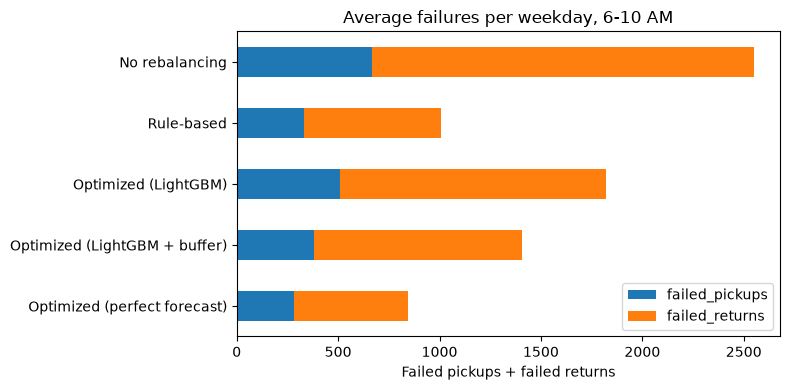

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
summary[['failed_pickups', 'failed_returns']].plot.barh(stacked=True, ax=ax)
ax.invert_yaxis()
ax.set_title('Average failures per weekday, 6-10 AM')
ax.set_xlabel('Failed pickups + failed returns')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

### Rebalancing plan for the first test day
Change in starting inventory from the LightGBM + buffer plan. Blue stations receive bikes (morning outflow stations); red stations give bikes up to free docks (morning inflow stations).

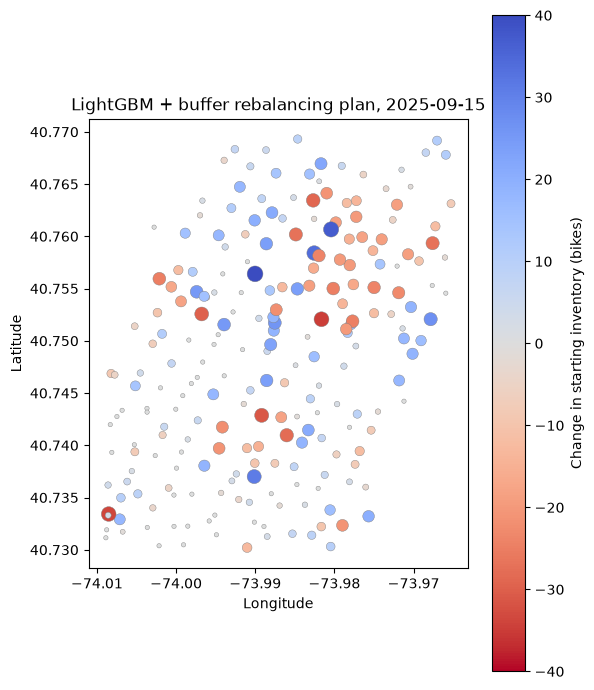

In [15]:
first_day = test_days[0]
change = lgbm_plans[first_day]['start'] - s0

fig, ax = plt.subplots(figsize=(6, 7))
sc = ax.scatter(stations['lng'], stations['lat'], c=change, cmap='coolwarm_r',
                vmin=-np.abs(change).max(), vmax=np.abs(change).max(),
                s=10 + np.abs(change) * 3, edgecolor='gray', linewidth=0.3)
fig.colorbar(sc, ax=ax, label='Change in starting inventory (bikes)')
ax.set_title(f'LightGBM + buffer rebalancing plan, {first_day.date()}')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_aspect(1 / np.cos(np.radians(40.75)))
plt.tight_layout()
plt.show()

**Key findings: test results**
- _To be filled after running._

## 7. Save outputs

### Save simulation results
One row per test weekday and strategy.

In [16]:
duckdb.sql(f"""
COPY results TO '{processed_dir}/rebalancing_results.parquet' (FORMAT PARQUET)
""")